<a href="https://colab.research.google.com/github/igupansini/utfpr-AI/blob/main/POSIA05-Redes_Neurais_Artificiais/Tarefa_MLPClassifier_Bebidas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exercício MLPClassifier - Bebidas

Rede Perceptron Multicamadas (MLP) utilizada como classificadora de padrões, com o objetivo de identificar qual tipo de conservante (A, B ou C) deve ser aplicado em determinado lote de bebida, a partir das quatro variáveis medidas em laboratório {x1, x2, x3, x4}: teor de água, grau de acidez, temperatura e tensão superficial. A rede é constituída de duas camadas neurais (uma camada oculta e uma camada de saída com três neurônios {y1, y2, y3}), conforme a topologia apresentada na Figura 1 do enunciado.

Padronização da saída: Tipo A = (1, 0, 0) - Tipo B = (0, 1, 0) - Tipo C = (0, 0, 1).

Dataset de treinamento: 130 amostras (bebidas.csv) - Dataset de validação: 18 amostras (bebidasTestes.csv). Ambos já normalizados.

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn import metrics
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
import seaborn as sns

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Carregamento e Organização Inicial do Dataset

In [ ]:
df_treino = pd.read_csv("/content/drive/MyDrive/UTFPR_IA/bebidas.csv")
df_teste = pd.read_csv("/content/drive/MyDrive/UTFPR_IA/bebidasTestes.csv")

print('Amostras de treinamento:', df_treino.shape)
print('Amostras de validação:', df_teste.shape)
df_treino.head()

Amostras de treinamento: (130, 7)
Amostras de validação: (18, 7)


,x1,x2,x3,x4,d1,d2,d3
0,0.3841,0.2021,0.0000,0.2438,1,0,0
1,0.1765,0.1613,0.3401,0.0843,1,0,0
2,0.3170,0.5786,0.3387,0.4192,0,1,0
3,0.2467,0.0337,0.2699,0.3454,1,0,0
4,0.6102,0.8192,0.4679,0.4762,0,1,0


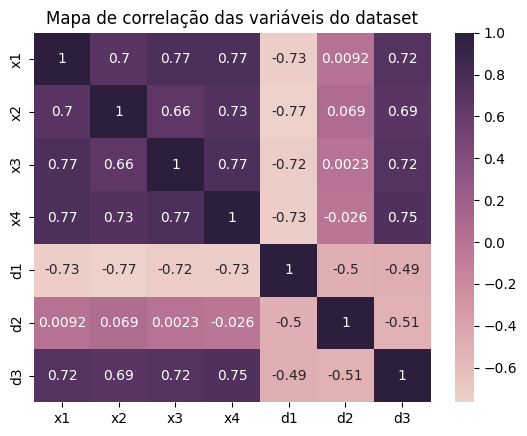

In [ ]:
# Gera um gráfico matricial para apresentar a correlação entre as variáveis do dataset
ax = sns.heatmap(df_treino.corr(numeric_only=True), annot=True, cmap=sns.cubehelix_palette(as_cmap=True))
ax.set_title('Mapa de correlação das variáveis do dataset')
ax=ax

Pré-Processamento dos Dados

Aqui não é aplicado StandardScaler() nem MinMaxScaler(). O enunciado informa que as variáveis {x1, x2, x3, x4} já estão normalizadas, e as saídas desejadas {d1, d2, d3} já estão codificadas com 0 e 1 conforme a padronização dos conservantes.

Também não é utilizado train_test_split(), pois o conjunto de validação já foi fornecido separadamente pelo enunciado (tabela de 18 amostras).

As saídas desejadas são mantidas nas três colunas {d1, d2, d3}. Dessa forma o MLPClassifier monta a camada de saída com três neurônios, também com função de ativação logística, conforme a Figura 1 do enunciado.

In [ ]:
trainX = df_treino[['x1', 'x2', 'x3', 'x4']]
trainY = df_treino[['d1', 'd2', 'd3']]

testX = df_teste[['x1', 'x2', 'x3', 'x4']]
testY = df_teste[['d1', 'd2', 'd3']]

df_treino.describe()

,x1,x2,x3,x4,d1,d2,d3
count,130.000000,130.000000,130.000000,130.000000,130.000000,130.000000,130.000000
mean,0.508730,0.536464,0.496789,0.449915,0.323077,0.346154,0.330769
std,0.221545,0.240517,0.219725,0.204357,0.469461,0.477583,0.472310
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.346075,0.366375,0.334725,0.303000,0.000000,0.000000,0.000000
50%,0.517700,0.521900,0.505800,0.447200,0.000000,0.000000,0.000000
75%,0.676325,0.721850,0.653500,0.612400,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Item 1 - Aplicação do MLPClassifier nos 3 Treinamentos

Variação da quantidade de neurônios da camada oculta (5, 10 e 15), totalizando 3 treinamentos. Em todos eles a função de ativação é a logística, a taxa de aprendizagem é 0.001, a precisão (épsilon) é 10⁻⁶ e a quantidade máxima de épocas é 5000, sendo as demais configurações mantidas no padrão do MLPClassifier. A melhor configuração é a que termina o treinamento com a menor perda.

Observação: como os pesos iniciais da rede são sorteados aleatoriamente e nenhuma semente é fixada, os valores de perda final e de épocas mudam a cada nova execução, podendo alterar a ordem do ranking.

In [ ]:
neuronios = [5, 10, 15]

resultados = []
modelos = {}
treinamento = 0

for n in neuronios:
    treinamento = treinamento + 1
    mlp = MLPClassifier(hidden_layer_sizes=(n), activation='logistic', solver='adam',
                        learning_rate_init=0.001, epsilon=1e-6, max_iter=5000)

    # Execução do treinamento da RNA
    mlp.fit(trainX, trainY)

    modelos['T' + str(treinamento)] = mlp
    resultados.append({'Treinamento': 'T' + str(treinamento),
                       'Neurônios': n,
                       'Perda Final': mlp.loss_,
                       'Número de Épocas': mlp.n_iter_,
                       'Acurácia no Treinamento (%)': metrics.accuracy_score(trainY, mlp.predict(trainX)) * 100})

    print('T' + str(treinamento), '-', n, 'neurônios - Perda Final:', round(mlp.loss_, 8),
          '- Épocas:', mlp.n_iter_, '- Ativação da camada de saída:', mlp.out_activation_)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


T1 - 5 neurônios - Perda Final: 0.68616445 - Épocas: 5000 - Ativação da camada de saída: logistic


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


T2 - 10 neurônios - Perda Final: 0.31123368 - Épocas: 5000 - Ativação da camada de saída: logistic
T3 - 15 neurônios - Perda Final: 0.28614654 - Épocas: 4335 - Ativação da camada de saída: logistic


In [ ]:
tabela = pd.DataFrame(resultados)
tabela['Ranking'] = tabela['Perda Final'].rank(method='min').astype(int) # Classifica as configurações da menor para a maior perda final
tabela

,Treinamento,Neurônios,Perda Final,Número de Épocas,Acurácia no Treinamento (%),Ranking
0,T1,5,0.686164,5000,73.846154,3
1,T2,10,0.311234,5000,94.615385,2
2,T3,15,0.286147,4335,94.615385,1


In [ ]:
ranking = tabela.sort_values('Ranking')
print(ranking.to_string(index=False))

melhor = ranking.iloc[0]
mlp_melhor = modelos[melhor['Treinamento']] # Recupera o modelo treinado da melhor configuração

print('\nMelhor configuração:', melhor['Treinamento'],
      '-', melhor['Neurônios'], 'neurônios na camada oculta',
      '- Perda Final:', round(melhor['Perda Final'], 8),
      '- Épocas:', melhor['Número de Épocas'])

Treinamento  Neurônios  Perda Final  Número de Épocas  Acurácia no Treinamento (%)  Ranking
         T3         15     0.286147              4335                    94.615385        1
         T2         10     0.311234              5000                    94.615385        2
         T1          5     0.686164              5000                    73.846154        3

Melhor configuração: T3 - 15 neurônios na camada oculta - Perda Final: 0.28614654 - Épocas: 4335


Avaliação do Erro no Processo de Treinamento

Gráfico de perda (loss) de cada uma das três configurações, conforme solicitado, e na sequência a comparação das três curvas em um mesmo gráfico.

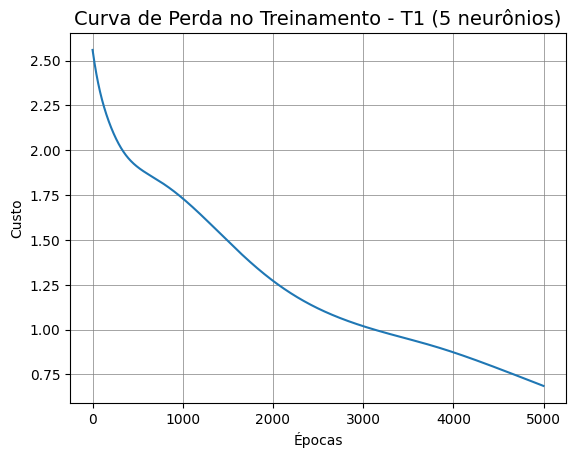

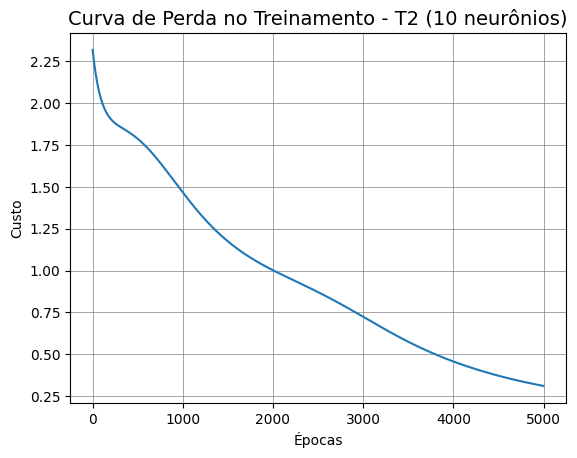

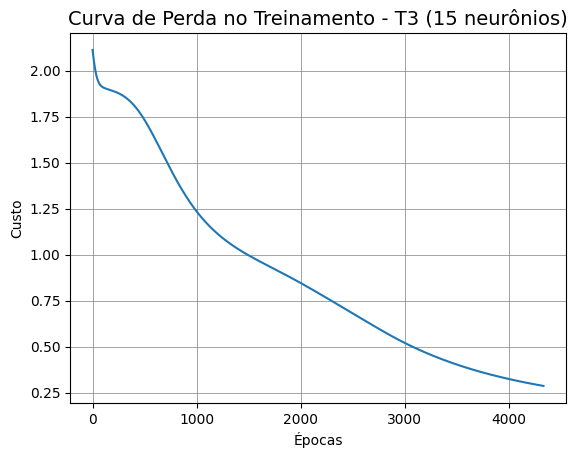

In [ ]:
for chave in modelos:
    linha = tabela[tabela['Treinamento'] == chave].iloc[0]
    plt.plot(modelos[chave].loss_curve_) # Plotando o gráfico de erros no processo de treinamento de cada configuração
    plt.title("Curva de Perda no Treinamento - " + chave + " (" + str(linha['Neurônios']) + " neurônios)", fontsize=14)
    plt.xlabel('Épocas')
    plt.ylabel('Custo')
    plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
    plt.show()

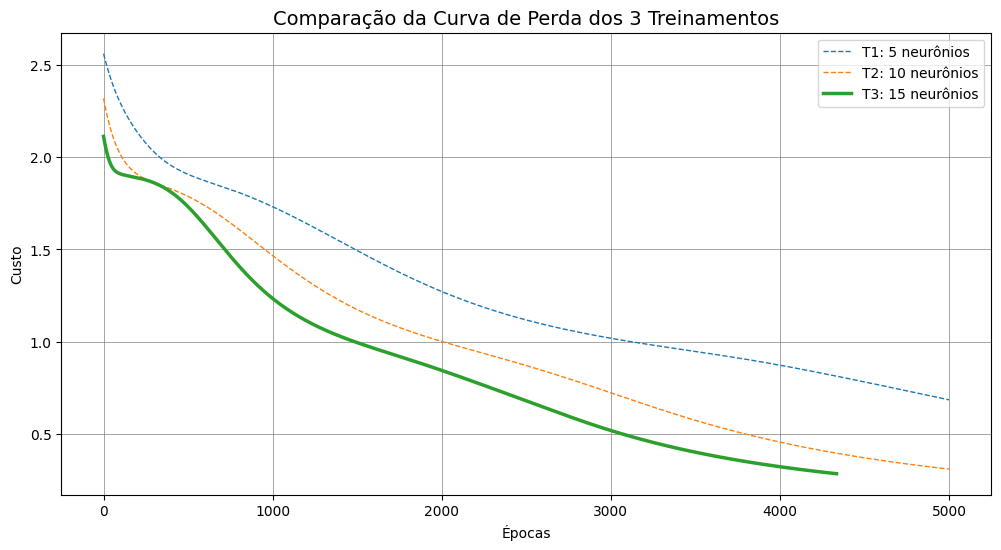

In [ ]:
plt.figure(figsize=(12,6))
for chave in modelos:
    linha = tabela[tabela['Treinamento'] == chave].iloc[0]
    plt.plot(modelos[chave].loss_curve_,
             linewidth = 2.5 if chave == melhor['Treinamento'] else 1.0,
             linestyle = '-' if chave == melhor['Treinamento'] else '--',
             label = chave + ': ' + str(linha['Neurônios']) + ' neurônios')

plt.title("Comparação da Curva de Perda dos 3 Treinamentos", fontsize=14)
plt.xlabel('Épocas')
plt.ylabel('Custo')
plt.legend()
plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.show()

Item 2 - Validação com o Conjunto de Teste

A melhor configuração obtida no Item 1 é aplicada ao conjunto de teste fornecido no enunciado, composto por 18 amostras que não participaram do treinamento. O MLPClassifier já fornece as saídas {y1, y2, y3} pós-processadas em 0 ou 1 (limiar de 0.5 sobre a saída logística de cada neurônio). Uma amostra só é considerada acerto quando as três saídas da rede coincidem com as saídas desejadas {d1, d2, d3}.

In [ ]:
y_pred = mlp_melhor.predict(testX)

conservantes = {(1, 0, 0): 'Tipo A', (0, 1, 0): 'Tipo B', (0, 0, 1): 'Tipo C'}

df_temp = testY.copy()
df_temp[['y1', 'y2', 'y3']] = y_pred
df_temp.index = df_temp.index + 1
df_temp.index.name = 'Amostra'
df_temp['Conservante Desejado'] = [conservantes[tuple(linha)] for linha in testY.values]
df_temp['Conservante Estimado'] = [conservantes.get(tuple(linha), 'Indefinido') for linha in y_pred] # Saída fora da padronização (nenhum ou mais de um neurônio ativo) é considerada indefinida
df_temp['Acerto'] = np.where(df_temp['Conservante Desejado'] == df_temp['Conservante Estimado'], 'Sim', 'Não')
df_temp

,d1,d2,d3,y1,y2,y3,Conservante Desejado,Conservante Estimado,Acerto
Amostra,,,,,,,,,
1,0,0,1,0,0,1,Tipo C,Tipo C,Sim
2,1,0,0,1,0,0,Tipo A,Tipo A,Sim
3,0,0,1,0,0,1,Tipo C,Tipo C,Sim
4,0,1,0,0,1,0,Tipo B,Tipo B,Sim
5,0,0,1,0,0,1,Tipo C,Tipo C,Sim
6,1,0,0,1,0,0,Tipo A,Tipo A,Sim
7,0,1,0,0,1,0,Tipo B,Tipo B,Sim
8,0,1,0,0,1,0,Tipo B,Tipo B,Sim
9,1,0,0,1,0,0,Tipo A,Tipo A,Sim


In [ ]:
print('Taxa de Acerto/Acurácia (%):', round(metrics.accuracy_score(testY, y_pred) * 100, 2))
print('Amostras classificadas corretamente:', (df_temp['Acerto'] == 'Sim').sum(), 'de', len(df_temp))
print('')
print('Relatório de classificação das amostras de teste:')
print(metrics.classification_report(testY, y_pred, target_names=['Tipo A', 'Tipo B', 'Tipo C'], zero_division=0))

Taxa de Acerto/Acurácia (%): 100.0
Amostras classificadas corretamente: 18 de 18

Relatório de classificação das amostras de teste:
              precision    recall  f1-score   support

      Tipo A       1.00      1.00      1.00         6
      Tipo B       1.00      1.00      1.00         5
      Tipo C       1.00      1.00      1.00         7

   micro avg       1.00      1.00      1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18
 samples avg       1.00      1.00      1.00        18



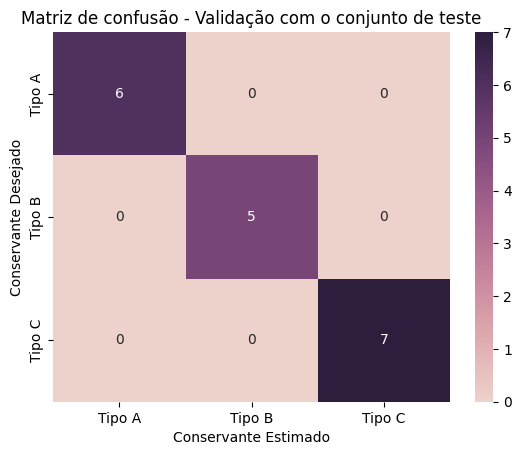

In [ ]:
# Gera a matriz de confusão entre o conservante desejado e o conservante estimado pela RNA
matriz = pd.crosstab(df_temp['Conservante Desejado'], df_temp['Conservante Estimado'])
ax = sns.heatmap(matriz, annot=True, cmap=sns.cubehelix_palette(as_cmap=True))
ax.set_title('Matriz de confusão - Validação com o conjunto de teste')
ax=ax

Conclusão

Os valores citados abaixo são os desta execução. Como nenhuma semente é fixada, uma nova execução produz números diferentes. Os pontos a observar são:

- O mapa de correlação mostra que d1 (Tipo A) tem correlação negativa forte com todas as entradas e d3 (Tipo C) tem correlação positiva forte, enquanto d2 (Tipo B) praticamente não se correlaciona com nenhuma delas, pois o Tipo B ocupa a faixa intermediária dos valores medidos. Por isso a saída y2 não pode ser obtida por uma única fronteira linear, o que justifica o uso da camada oculta.
- Item 1: a configuração com 15 neurônios na camada oculta (T3) apresentou a menor perda final (0.2861) e, portanto, o melhor desempenho. A de 10 neurônios (T2) ficou próxima, com 0.3112, e a de 5 neurônios (T1) terminou com perda bem maior, 0.6862.
- Sem semente fixa, os valores mudam a cada execução. A rede com 5 neurônios tende a ficar bem atrás das outras duas, mas como 10 e 15 neurônios terminam com perdas próximas, a ordem entre essas duas pode se inverter em alguma execução.
- Com 5 e 10 neurônios a rede chegou ao limite de 5000 épocas ainda reduzindo a perda, como mostram as curvas de T1 e T2 e os dois avisos ConvergenceWarning emitidos pelo sklearn. Apenas a rede com 15 neurônios parou antes, pelo critério de tolerância, em 4335 épocas. Com menos neurônios na camada oculta a rede tem menos capacidade para separar as três classes e converge mais devagar.
- Com 10 e 15 neurônios a acurácia no próprio conjunto de treinamento ficou em 94.62% (7 das 130 amostras erradas). Essas amostras ficam na fronteira entre dois tipos de conservante: nelas as saídas da rede ficam próximas de 0.5, e às vezes dois neurônios de saída são ativados ao mesmo tempo. Com 5 neurônios a acurácia no treinamento caiu para 73.85%, reflexo do treinamento que terminou sem convergir.
- Item 2: aplicando a melhor configuração (T3) às 18 amostras de teste, a taxa de acerto/acurácia foi de 100% (18 de 18), ou seja, todas as amostras receberam o tipo de conservante correto, sem nenhuma saída indefinida.